# 26. Recovering motion from two stereo pairs

[Course plan](../../README.md)

The blue end of the ribbon barely moves. The orange end lifts and settles back down. Two fixed cameras saw the ribbon a quarter and three quarters of a second into the clip. There are no training frames in between. Where will the orange splat appear at 0.375 s, seen from the side?

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "deformation.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import deformation as motion
import deformation_demos as demos
np.set_printoptions(precision=5, suppress=True)

## What the fit gets to see

The ribbon has the same five splats as before. Its rest shape, colors, initial positions and cameras are known. In the synthetic recording each center has a colored landmark. The fit receives the landmark IDs and their pixel coordinates. The generator keeps the actual 3D centers and a third camera’s images for evaluation. Finding matching landmarks in ordinary video would be a separate problem.

Camera and time move independently. The two alternatives are a static ribbon and a model fitted to the landmarks. Switching between them changes the picture on the right. The frame on the left still comes from the synthetic recording. Holding one control steady separates a change of viewpoint from a change of time before testing the two together.

In [2]:
display(demos.lab(26, "en"))

## Turning two pixels into one point

Both cameras have a focal length $f=64$ px and principal point $(32,24)$ px. The left camera is at the origin, the right camera displaced $B=0.8$ m to the right. Both look straight ahead. For the ribbon tip at 0.25 s, the horizontal pixel coordinates are 44.89417 on the left and 33.30390 on the right. Both vertical coordinates are 17.04584 px.

The horizontal difference is $d=44.89417-33.30390=11.59027$ px. The point has the same depth $Z$ in both views, so $d=fB/Z$. Moving $Z$ to the other side and dividing by $d$ gives $Z=64\cdot0.8/11.59027\approx4.4175$ m. Pixels cancel, leaving metres. Subtracting the principal point from the left coordinate and restoring the depth scale gives $X=(44.89417-32)\cdot4.4175/64\approx0.89$ m. Vertically, $Y=(17.04584-24)\cdot4.4175/64\approx-0.48$ m. The center has risen, hence the negative sign. Half a second later the second stereo pair gives $(0.89,-0.72,4.2575)$ m. The smaller the disparity, the more a one-pixel mistake matters.

In [3]:
observations = motion.stereo_tracks()
for row in observations:
    (ul, v), (ur, _) = row["left"][-1], row["right"][-1]
    z = motion.FOCAL * motion.BASELINE / (ul - ur)
    xyz = [(ul - 32)*z/64, (v - 24)*z/64, z]
    print(row["t"], "s  XYZ =", np.round(xyz, 5))

0.25 s  XYZ = [ 0.89   -0.48    4.4175]
0.75 s  XYZ = [ 0.89   -0.72    4.2575]


## A single rise in place of a pose for every frame

The ribbon has one second to leave its starting position and return. The fraction $r=t/T$ divides elapsed seconds by the duration $T=1$ s. At the beginning $r=0$ and at the end $r=1$. Their product $r(1-r)$ vanishes at each end and reaches $0.5\cdot0.5=0.25$ in the middle. Multiplying by four puts the peak at one. That gives a smooth, dimensionless arc $h=4r(1-r)$.

The canonical center $p_0$ is measured in metres. We add three offsets $a=(a_x,a_y,a_z)$ multiplied by the fraction $h$. The full offset applies halfway through the clip. At a quarter second the fraction is just $4\cdot0.25\cdot0.75=0.75$. Each splat gets its own three offsets.

$$
p(t)=p_0+h(t)\,a.
$$

The orange tip starts at height zero. Its two measured vertical offsets are −0.48 and −0.72 m, both at a height fraction of 0.75. Fitting them separately gives $-0.48/0.75=-0.64$ m and $-0.72/0.75=-0.96$ m. A single arc cannot hit both observations because the recorded ribbon also sways a little. With equal fractions, the midpoint minimizes the sum of squared errors: $(-0.64-0.96)/2=-0.8$ m.

At other times the fractions can differ. For one coordinate, let $d_k$ be the measured displacement and $a$ the amplitude. The index $k$ runs over the observations. The residual between prediction and measurement is $h_k a-d_k$ metres. Squaring each residual and adding them gives the loss. Differentiating the square brings down twice the residual. The slope of the residual with respect to $a$ contributes another factor of $h_k$. The slope at the bottom of this parabola is zero, giving

$$
\begin{aligned}
0 &= \sum_k 2h_k(h_k a-d_k),\\
a\sum_k h_k^2 &= \sum_k h_k d_k,\\
a &= \frac{\sum_k h_k d_k}{\sum_k h_k^2}.
\end{aligned}
$$

For vertical motion the numerator is $0.75(-0.48)+0.75(-0.72)=-0.9$ m. The denominator is $0.75^2+0.75^2=1.125$ and has no units. Division again gives −0.8 m. With only the first and last instant, both fractions vanish and the denominator is zero. Two frames of the ribbon at rest cannot reveal how high it rose.

In [4]:
model = motion.fit_motion(motion.ribbon(), observations)
print("a =", np.round(model["amplitudes"][-1], 5))
print("t = 0.375 s:", np.round(motion.scene_at(model, .375)["splats"][-1]["center"], 5))

a = [ 0.12 -0.8   0.45]
t = 0.375 s: [ 0.9125  -0.75     4.42188]


## Three separate checks

First come the left camera and time 0.375 s. The camera is familiar but the time is missing from the observations. Next come the training time 0.25 s and a camera angled at 32°. That tests a different change. The third check combines 0.375 s and 32°. In each row below, frame MSE averages squared errors over $65\cdot49\cdot3=9555$ channel values, with channel intensities from 0 to 1.

For the last splat at 0.375 s, the bend fraction is $h=4\cdot0.375\cdot0.625=0.9375$. Its predicted height is $0-0.8\cdot0.9375=-0.75$ m. The recorded motion puts it at $-0.66515$ m, so the estimate lifts the tip about 8.5 cm too high. At that same time in the unseen view, frame error falls from about 0.007119 for the static ribbon to 0.000364 for the fit. The bright edge on the difference map shows where the mismatch stands out against the background.

t        angle   MSE(static)   MSE(fitted)
0.375      0     0.00937542    0.00061671
0.250     32     0.00527760    0.00072072
0.375     32     0.00711925    0.00036425


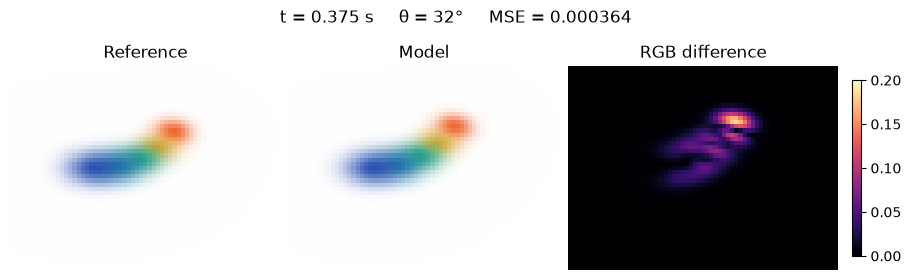

In [5]:
print("t        angle   MSE(static)   MSE(fitted)")
for time, angle in [(.375, 0), (.25, 32), (.375, 32)]:
    target = demos.frame(motion.reference_scene(time), angle)
    static = demos.frame(model["canonical"], angle)
    fitted = demos.frame(motion.scene_at(model, time), angle)
    print(f"{time:.3f}    {angle:3}     {np.mean((static-target)**2):.8f}    {np.mean((fitted-target)**2):.8f}")
fig = demos.fit_figure(lang="en")
plt.show()

## What happens between samples

At 0.25, 0.5 and 0.75 s, the modeled height of the last splat is −0.6, −0.8 and −0.6 m. Average velocity over the first interval is $(-0.8+0.6)/0.25=-0.8$ m/s. Over the next it is $(-0.6+0.8)/0.25=+0.8$ m/s. The sign flips as the tip turns. A single smooth arc spans the entire second, so there is no jump at a frame boundary. The graph also shows a cost of this assumption. The two black landmarks have different heights, but a symmetric arc always returns the same height a quarter and three quarters of the way through. A motion error can survive even when mean image error is small.

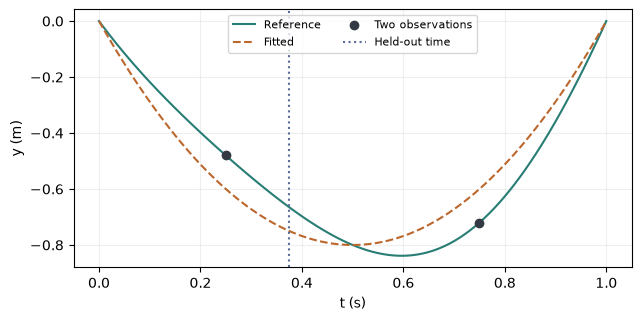

In [6]:
fig = demos.motion_plot(lang="en")
plt.show()

## What goes in the file

Playback needs the rest ribbon, the duration in seconds and five amplitude triplets. Images and landmarks can stay behind. After saving and reloading, the same time and camera should give the same frame. The browser accepts this format in “Motion from JSON”. Opening a custom file puts its canonical scene on the left. Without a reference recording there is no MSE to report.

In [7]:
folder = root / "dynamic-scene-result"
folder.mkdir(exist_ok=True)
path = folder / "lesson-26-en.json"
path.write_text(json.dumps(model, allow_nan=False), encoding="utf8")
restored = motion.validate_model(json.loads(path.read_text(encoding="utf8")))
np.testing.assert_array_equal(demos.frame(motion.scene_at(restored, .375), 32),
                              demos.frame(motion.scene_at(model, .375), 32))
print(path.name, "·", len(restored["amplitudes"]), "× XYZ")

lesson-26-en.json · 5 × XYZ


## A noisy landmark

Suppose the right landmark at 0.25 s moves horizontally by +1 px and the left one stays fixed. Which way will the reconstructed point move? Must the fitted arc pass through it?

<details>
<summary>Worked answer</summary>

The disparity falls from 11.59027 to 10.59027 px. With the same numerator of 51.2, depth becomes $51.2/10.59027\approx4.835$ m. The point lands about 42 cm behind its original depth of 4.4175 m. The vertical pixel coordinate was unchanged, but converting it to metres now uses the new depth. The arc still has one amplitude per coordinate for two measurements, so it makes a compromise. The noise control introduces alternating positive and negative offsets into the right landmarks, keeping the experiment repeatable.

</details>